# CELLxGENE scRNA-seq reference for spatial transcriptomics scoring

In [22]:
import cellxgene_census
import pandas as pd
import numpy as np

OBS_COLS = [
    "dataset_id",
    "assay",
    "cell_type",
    "tissue",
    "tissue_general",
    "disease",
    "suspension_type",
    "donor_id",
    "is_primary_data",
    "n_measured_vars",
]

with cellxgene_census.open_soma() as census:
    datasets = (
        census["census_info"]["datasets"]
        .read()
        .concat()
        .to_pandas()
    )

    organism_obs = []

    for organism in census["census_data"].keys():
        print(f"Reading obs metadata for {organism}")

        obs = (
            census["census_data"][organism]
            .obs
            .read(column_names=OBS_COLS,value_filter="is_primary_data == True")
            .concat()
            .to_pandas()
        )

        obs["organism"] = organism
        obs = obs[obs['is_primary_data'].fillna(False)].copy()
        organism_obs.append(obs)
cell_meta = pd.concat(organism_obs, ignore_index=True)

summary = (
    cell_meta
    .groupby("dataset_id")
    .agg(
        n_cells=("dataset_id", "size"),
        assays=("assay", lambda x: sorted(x.dropna().unique())),
        tissues=("tissue", lambda x: sorted(x.dropna().unique())),
        tissue_general=("tissue_general", lambda x: sorted(x.dropna().unique())),
        diseases=("disease", lambda x: sorted(x.dropna().unique())),
        cell_types=("cell_type", lambda x: sorted(x.dropna().unique())),
        organisms=("organism", lambda x: sorted(x.dropna().unique())),
        suspension_types=("suspension_type", lambda x: sorted(x.dropna().unique())),
        n_donors=("donor_id", lambda x: x.dropna().nunique()),
        median_n_measured_vars=("n_measured_vars", "median"),
    )
    .reset_index()
)

summary = summary.merge(
    datasets,
    on="dataset_id",
    how="inner",   # important: avoid metadata-only rows with no obs rows
)

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


Reading obs metadata for callithrix_jacchus
Reading obs metadata for homo_sapiens
Reading obs metadata for macaca_mulatta
Reading obs metadata for mus_musculus
Reading obs metadata for pan_troglodytes


In [23]:
summary

,dataset_id,n_cells,assays,tissues,tissue_general,diseases,cell_types,organisms,suspension_types,n_donors,...,soma_joinid,citation,collection_id,collection_name,collection_doi,collection_doi_label,dataset_version_id,dataset_title,dataset_h5ad_path,dataset_total_cell_count
0,00476f9f-ebc1-4b72-b541-32f912ce36ea,10099,[10x 3' v3],[hypothalamus],[brain],[normal],"[astrocyte, central nervous system macrophage,...",[homo_sapiens],[nucleus],1,...,667,Publication: https://doi.org/10.1126/science.a...,283d65eb-dd53-496d-adb7-7570c7caa443,Human Brain Cell Atlas v1.0,10.1126/science.add7046,Siletti et al. (2023) Science,03dd07cf-c654-4f5a-8852-3e055fd7b27d,Dissection: Hypothalamus (HTH) - mammillary re...,00476f9f-ebc1-4b72-b541-32f912ce36ea.h5ad,10099
1,0087cde2-967d-4f7c-8e6e-40e4c9ad1891,5399,[10x 3' v3],[neocortex],[brain],[normal],[L2/3-6 intratelencephalic projecting glutamat...,[homo_sapiens],[cell],78,...,1209,Publication: https://doi.org/10.1126/science.a...,35928d1c-36fc-4f93-9a8d-0b921ab41745,HVS: Human variation study,10.1126/science.adf2359,Johansen et al. (2023) Science,14efaa91-e026-40b9-93b7-088d2ead3199,L6ITCar3 - neocortex: Human variation study (HVS),0087cde2-967d-4f7c-8e6e-40e4c9ad1891.h5ad,5399
2,01209dce-3575-4bed-b1df-129f57fbc031,51876,[10x 3' v2],"[bone marrow, bronchopulmonary lymph node, low...","[blood, bone marrow, lung, lymph node]",[normal],"[CD4-positive, alpha-beta T cell, CD4-positive...",[homo_sapiens],[cell],4,...,1006,Publication: https://doi.org/10.1038/s41467-01...,24d42e5e-ce6d-45ff-a66b-a3b3b715deaf,Single-cell transcriptomics of human T cells r...,10.1038/s41467-019-12464-3,Szabo et al. (2019) Nat Commun,b4f8de4e-caf6-403c-a261-4e5298bb4707,Single-cell transcriptomics of human T cells r...,01209dce-3575-4bed-b1df-129f57fbc031.h5ad,51876
3,0129dbd9-a7d3-4f6b-96b9-1da155a93748,244474,[10x 3' v3],"[fovea centralis, macula lutea proper, periphe...",[eye],[normal],"[amacrine cell, glial cell, retina horizontal ...",[homo_sapiens],[nucleus],6,...,1823,Publication: https://doi.org/10.1016/j.xgen.20...,af893e86-8e9f-41f1-a474-ef05359b1fb7,Single-cell transcriptomic atlas for adult hum...,10.1016/j.xgen.2023.100298,Liang et al. (2023) Cell Genomics,d4f1a799-9616-4089-90e9-f3fe843f01e5,All major cell types in adult human retina,0129dbd9-a7d3-4f6b-96b9-1da155a93748.h5ad,244474
4,019c7af2-c827-4454-9970-44d5e39ce068,12590,[10x 3' v3],"[ascending colon, descending colon, duodenum, ...","[colon, small intestine]",[normal],"[BEST4+ enterocyte, colon goblet cell, enteroc...",[homo_sapiens],[cell],3,...,1557,Publication: https://doi.org/10.1016/j.jcmgh.2...,64b24fda-6591-4ce1-89e7-33eb6c43ad7b,A proximal-to-distal survey of healthy adult h...,10.1016/j.jcmgh.2022.02.007,Burclaff et al. (2022) Cellular and Molecular ...,45a7d3bd-dc1a-4565-8881-25f8975247a6,A proximal-to-distal survey of healthy adult h...,019c7af2-c827-4454-9970-44d5e39ce068.h5ad,12590
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
640,fd072bc3-2dfb-46f8-b4e3-467cb3223182,610392,"[10x 3' v2, 10x 5' v1]","[kidney, liver, skin of body, spleen, thymus, ...","[endocrine gland, kidney, liver, skin of body,...",[normal],"[B-1 B cell, B-2 B cell, CD8-alpha-alpha-posit...",[homo_sapiens],[cell],20,...,1794,Publication: https://doi.org/10.1126/science.a...,b1a879f6-5638-48d3-8f64-f6592c1b1561,Mapping the developing human immune system acr...,10.1126/science.abo0510,Suo et al. (2022) Science,4eb0a1aa-216c-4f22-93ab-85e95ed70cbb,Full dataset of single-cell RNA-seq profiles f...,fd072bc3-2dfb-46f8-b4e3-467cb3223182.h5ad,908046
641,fe1a73ab-a203-45fd-84e9-0f7fd19efcbd,35285,[10x 3' v3],[cerebral nuclei],[brain],[normal],"[astrocyte, central nervous system macrophage,...",[homo_sapiens],[nucleus],3,...,1100,Publication: https://doi.org/10.1126/science.a...,283d65eb-dd53-496d-adb7-7570c7caa443,Human Brain Cell Atlas v1.0,10.1126/science.add7046,Siletti et al. (2023) Science,17060c76-b604-4b14-b17b-8223d85f72a2,Dissection

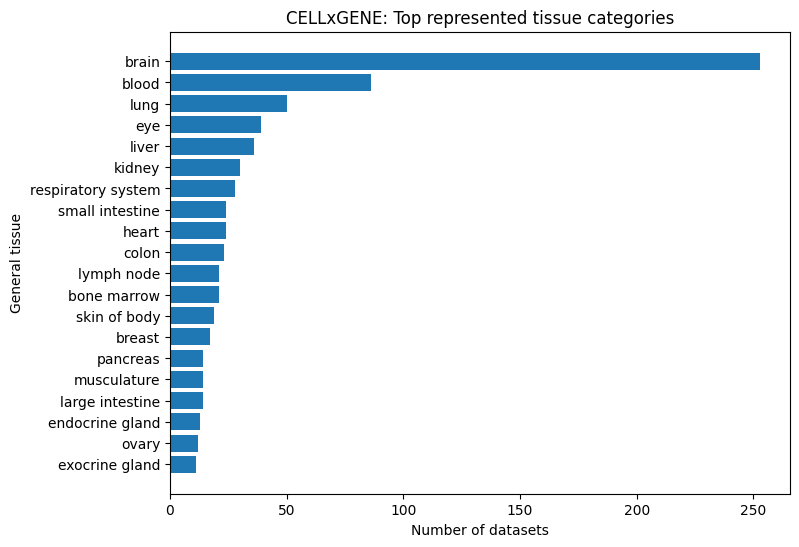

In [24]:
import matplotlib.pyplot as plt
def explode_list_column(df, col):
    tmp = df[["dataset_id", col]].copy()
    tmp[col] = tmp[col].apply(lambda x: x if isinstance(x, list) else [])
    return tmp.explode(col).dropna()

tissue_counts = (
    explode_list_column(summary, "tissue_general")
    .query("tissue_general != ''")
    .groupby("tissue_general")
    .size()
    .sort_values(ascending=False)
    .head(20)
    .sort_values()
)

plt.figure(figsize=(8, 6))
plt.barh(tissue_counts.index, tissue_counts.values)
plt.xlabel("Number of datasets")
plt.ylabel("General tissue")
plt.title("CELLxGENE: Top represented tissue categories")
plt.show()

In [25]:
def preview_list(x, n=4):
    if not isinstance(x, list):
        return x
    if len(x) <= n:
        return ", ".join(map(str, x))
    return ", ".join(map(str, x[:n])) + f", ... ({len(x)} total)"

display_cols = [
    "dataset_id",
    "collection_id",
    "collection_name",
    "dataset_title",
    "n_cells",
    "assays",
    "tissues",
    "tissue_general",
    "diseases",
    "suspension_types",
    "n_donors",
    "median_n_measured_vars",
]

summary_display = summary.copy()
for col in ["assays", "tissues", "tissue_general", "diseases", "suspension_types", "cell_types"]:
    summary_display[col] = summary_display[col].apply(preview_list)

summary_display[display_cols].sort_values("n_cells", ascending=False).head(20)

,dataset_id,collection_id,collection_name,dataset_title,n_cells,assays,tissues,tissue_general,diseases,suspension_types,n_donors,median_n_measured_vars
549,dcfd4feb-18a3-4b30-81d7-1b0c544a8ab3,45d5d2c3-bc28-4814-aed6-0bb6f0e11c82,A single-cell transcriptional timelapse of mou...,Whole dataset: Raw counts only,11441407,sci-RNA-seq3,embryo,embryo,normal,nucleus,74,45525.0
143,37a17b78-4864-4a42-b67b-31c00962795a,84ce6837-548d-4a1f-919f-0bc0d9a3952f,Population-scale cross-disorder atlas of the h...,MSSM_Cohort,4140453,10x 3' v3,dorsolateral prefrontal cortex,brain,"Lewy body dementia, Parkinson disease, amyotro...",nucleus,1042,34176.0
627,f7c1c579-2dc0-47e2-ba19-8165c5a0e353,c114c20f-1ef4-49a5-9c2e-d965787fb90c,A human cell atlas of fetal gene expression,Survey of human embryonic development,4062980,sci-RNA-seq3,"adrenal gland, cerebellum, eye, heart, ... (15...","adrenal gland, brain, endocrine gland, eye, .....","normal, trisomy 18","cell, nucleus",28,45676.0
528,d6505c89-c43d-4c28-8c4f-7351a5fd5528,4c6eaf5c-6d57-4c76-b1e9-60df8c655f1e,Single cell atlas of the human retina,snRNA-seq of human retina - all cells,2907910,10x 3' v3,"fovea centralis, macula lutea, macula lutea pr...",eye,normal,nucleus,100,35475.0
188,46104f0b-9af5-466a-ae0f-56b8dc1969a2,e9360edf-b0b7-4e01-bce8-e596814f13e7,Multi-omic profiling reveals age-related immun...,"Sound Life Young Adult Females, CMV-negative",2616824,10x 3' v3,blood,blood,normal,cell,18,32357.0
430,aa32098f-f7b0-43f2-a00a-601d190aae94,e9360edf-b0b7-4e01-bce8-e596814f13e7,Multi-omic profiling reveals age-related immun...,"Sound Life Older Adult Females, CMV-positive",2596111,10x 3' v3,blood,blood,cytomegalovirus infection,cell,17,32357.0
537,d87ba7ec-fddf-4141-abfd-1d69e8427a42,8c4bcf0d-b4df-45c7-888c-74fb0013e9e7,A single-cell transcriptomic atlas spanning th...,A single-cell multi-omic atlas spanning the ad...,2583967,sci-RNA-seq3,"Brodmann (1909) area 19, amygdala, anterior ci...",brain,normal,nucleus,5,29060.0
519,d3cb449b-c2b1-4b50-a7f1-21203535fe61,d5d0df8f-4eee-49d8-a221-a288f50a1590,A multi-region single nucleus transcriptomic a...,Parkinson's disease,2096155,10x 3' v3,"dorsal motor nucleus of vagus nerve, medial gl...",brain,"Parkinson disease, normal",nucleus,97,17266.0
399,9f222629-9e39-47d0-b83f-e08d610c7479,6f6d381a-7701-4781-935c-db10d30de293,The integrated Human Lung Cell Atlas,An integrated cell atlas of the human lung in ...,1926653,"10x 3' v1, 10x 3' v2, 10x 3' v3, 10x 5' transc...","lung, lung parenchyma, nose, respiratory airway","lung, nose, respiratory system","COVID-19, chronic obstructive pulmonary diseas...","cell, nucleus",439,55329.0
536,d7f5d8d0-6150-48d7-b094-c34286ad11a1,de379e5f-52d0-498c-9801-0f850823c847,An integrated transcriptomic cell atlas of hum...,HNOCA Extended: The Human Neural Organoid Atlas,1920454,"10x 3' v2, 10x 3' v3, 10x multiome, BD Rhapsod...","arcuate nucleus of hypothalamus, brain, cerebe...",brain,normal,"cell, nucleus",55,35725.0


In [26]:
from cellxgene_quantification import is_spatial_dataset
import cellxgene_quantification
import importlib
importlib.reload(cellxgene_quantification)
spatial_meta = summary[summary.apply(is_spatial_dataset, axis=1)].copy()

spatial_meta[
    [
        "dataset_id",
        "dataset_title",
        "collection_name",
        "assays",
        "tissues",
        "tissue_general",
        "diseases",
        "dataset_total_cell_count",
        "n_cells",
    ]
]

,dataset_id,dataset_title,collection_name,assays,tissues,tissue_general,diseases,dataset_total_cell_count,n_cells
8,02792605-4760-4023-82ad-40fc4458a5db,All cells types from scRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,[10x 5' v2],[caudate lobe of liver],[liver],"[primary biliary cholangitis, primary sclerosi...",89637,65396
35,0c9a8cfb-6649-4d52-b418-6d8e56bd7afe,Cholangiocytes from human healthy donor liver ...,Single-cell and spatial transcriptomics charac...,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],1011,832
61,1873a18a-66fd-4a4d-8277-a872c93f5b59,All cells types from snRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,[10x 3' v3],[caudate lobe of liver],[liver],"[primary biliary cholangitis, primary sclerosi...",105780,79265
80,1e4214ce-7347-4ec7-97b3-fcf7c1938e8b,Lung cancer 4 patients archival FFPE samples p...,Transcriptome Analysis of Archived Tumor Tissu...,[10x gene expression flex],[lung parenchyma],[lung],"[lung adenocarcinoma, squamous cell lung carci...",35954,35954
94,234c23d0-d6cd-4612-a40d-e5811727564b,Hepatocyte-1 cells from human healthy donor li...,Single-cell and spatial transcriptomics charac...,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],53015,45186
111,2a65bd41-4a3f-42f4-98b2-c53962811152,Ovarian tissue from donor 4,Cellular atlas of the human ovary using morpho...,[10x 3' v3],[ovary],[ovary],[normal],7288,7288
179,43560d7c-acd6-4ede-830d-c9ffc6cd0862,Natural killer T cells from human healthy dono...,Single-cell and spatial transcriptomics charac...,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],16665,15216
199,4993d61c-1d04-4630-9c61-8d9431f39adc,B cells from human healthy donor liver samples,Single-cell and spatial transcriptomics charac...,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],1250,1167
207,4ce8d8ec-b94c-4b79-afcb-b094336d8a78,Endothelial cells from human healthy donor liv...,Single-cell and spatial transcriptomics charac...,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],9422,8219
301,76af615b-12fe-4ebb-b8c6-239ad29e26e3,Hepatocyte-2 cells from human healthy donor li...,Single-cell and spatial transcriptomics charac...,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],13635,11982


In [27]:
from cellxgene_quantification import is_probably_scrna_reference, find_best_references_for_spatial_dataset
import importlib
import cellxgene_quantification
importlib.reload(cellxgene_quantification)
# Candidate scRNA/snRNA references from CELLxGENE summary table
ref_meta = summary[summary.apply(is_probably_scrna_reference, axis=1)].copy()

# Optional: remove metadata-only rows with no aggregated obs information
ref_meta = ref_meta[ref_meta["n_cells"] > 0].copy()

all_scores = []

for _, st_row in spatial_meta.iterrows():
    top_refs = find_best_references_for_spatial_dataset(
        st_row=st_row,
        ref_meta=ref_meta,
        top_k=10,
    )
    all_scores.append(top_refs)

reference_scores = pd.concat(all_scores, ignore_index=True)

In [28]:
reference_scores

,spatial_dataset_id,ref_dataset_id,ref_dataset_title,ref_collection_name,ref_collection_id,score,tier,tissue_score,disease_score,celltype_score,quality_score,same_study_score,ref_n_cells,ref_n_donors,ref_assays,ref_tissues,ref_tissue_general,ref_diseases,ref_organism
0,02792605-4760-4023-82ad-40fc4458a5db,1873a18a-66fd-4a4d-8277-a872c93f5b59,All cells types from snRNA-seq of human primar...,Single-cell and spatial transcriptomics charac...,0c8a364b-97b5-4cc8-a593-23c38c6f0ac5,0.877778,A: strong matched reference,1.0,1.00,0.592593,1.000000,1.0,79265,9,[10x 3' v3],[caudate lobe of liver],[liver],"[primary biliary cholangitis, primary sclerosi...",[homo_sapiens]
1,02792605-4760-4023-82ad-40fc4458a5db,84cfa5aa-a0d1-415e-ac47-eb66c9cf8170,Healthy and IFALD pediatric and adult human li...,Single-Cell Atlas Of Human Pediatric Liver Rev...,ff69f0ee-fef6-4895-9f48-6c64a68c8289,0.595861,C: partial reference,1.0,0.35,0.407407,1.000000,0.0,72710,15,"[10x 3' v2, 10x 3' v3, 10x 5' v2]","[caudate lobe of liver, left lobe of liver, li...",[liver],"[intestinal failure–associated liver disease, ...",[homo_sapiens]
2,02792605-4760-4023-82ad-40fc4458a5db,ddb22b3d-a75c-4dd1-9730-dff7fc8ca530,Healthy human liver: integrated,"Single-Cell, Single-Nucleus, and Spatial RNA S...",44531dd9-1388-4416-a117-af0a99de2294,0.549268,C: partial reference,1.0,0.35,0.259259,0.925000,0.0,73295,4,"[10x 3' v2, 10x 3' v3]",[caudate lobe of liver],[liver],[normal],[homo_sapiens]
3,02792605-4760-4023-82ad-40fc4458a5db,43560d7c-acd6-4ede-830d-c9ffc6cd0862,Natural killer T cells from human healthy dono...,Single-cell and spatial transcriptomics charac...,0c8a364b-97b5-4cc8-a593-23c38c6f0ac5,0.540735,C: partial reference,1.0,0.35,0.222222,0.458916,1.0,15216,23,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],[homo_sapiens]
4,02792605-4760-4023-82ad-40fc4458a5db,234c23d0-d6cd-4612-a40d-e5811727564b,Hepatocyte-1 cells from human healthy donor li...,Single-cell and spatial transcriptomics charac...,0c8a364b-97b5-4cc8-a593-23c38c6f0ac5,0.534302,C: partial reference,1.0,0.35,0.111111,0.925116,1.0,45186,23,"[10x 3' v2, 10x 5' v1]",[caudate lobe of liver],[liver],[normal],[homo_sapiens]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
165,fbdd8c17-b34a-4cbc-abc4-1aeaa294a538,68b6114f-e990-4033-bfb3-c35536633aaa,Stromal cell diversity associated with immune ...,Stromal cell diversity associated with immune ...,16a4f6bc-2457-4e21-9b7a-9ba17c7b66c4,0.261499,D: weak reference,0.6,0.00,0.157895,0.599771,0.0,24271,5,[10x 3' v2],[mammary gland connective tissue],[exocrine gland],[triple-negative breast carcinoma],[homo_sapiens]
166,fbdd8c17-b34a-4cbc-abc4-1aeaa294a538,a82c43bb-a703-446d-aa24-049bf013121f,10X_5-rep2,Comparative Analysis of Commercial Single-Cell...,398e34a9-8736-4b27-a9a7-31a47a67f446,0.000000,E: no metadata-supported reference,0.0,0.35,0.157895,0.042778,0.0,7750,1,[10x 5' v2],[blood],[blood],[normal],[homo_sapiens]
167,fbdd8c17-b34a-4cbc-abc4-1aeaa294a538,a84face4-eb30-4f43-994f-c6a13a097808,Dissection: Cerebral cortex (Cx) - Cingulate g...,Human Brain Cell Atlas v1.0,283d65eb-dd53-496d-adb7-7570c7caa443,0.000000,E: no metadata-supported reference,0.0,0.35,0.052632,0.602324,0.0,34078,3,[10x 3' v3],[cerebral cortex],[brain],[normal],[homo_sapiens]
168,fbdd8c17-b34a-4cbc-abc4-1aeaa294a538,a9bedd04-51cb-42ad-83fe-cd749de71f1b,Ovarian tissue from donor 3,Cellular atlas of the human ovary using morpho...,6686ada5-43a8-40b6-9a05-6894503606db,0.000000,E: no metadata-supported reference,0.0,0.35,0.052632,0.039993,0.0,7571,1,[10x 3' v3],[ovary],[ovary],[normal],[homo_sapiens]


In [29]:
def plot_reference_score_report(reference_scores):
    scores = reference_scores.copy()

    numeric_cols = [
        "score",
        "tissue_score",
        "disease_score",
        "celltype_score",
        "quality_score",
        "same_study_score",
        "ref_n_cells",
        "ref_n_donors",
    ]

    for col in numeric_cols:
        if col in scores.columns:
            scores[col] = pd.to_numeric(scores[col], errors="coerce")

    best_refs = (
        scores
        .sort_values(["spatial_dataset_id", "score"], ascending=[True, False])
        .groupby("spatial_dataset_id")
        .head(1)
        .reset_index(drop=True)
    )

    component_cols = [
        "tissue_score",
        "disease_score",
        "celltype_score",
        "quality_score",
        "same_study_score",
    ]

    # 1. Best score histogram
    plt.figure(figsize=(7, 4))
    plt.hist(best_refs["score"].dropna(), bins=25)
    plt.xlabel("Best available scRNA-seq reference score")
    plt.ylabel("Number of spatial datasets")
    plt.title("Distribution of best reference scores")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

    # 2. Tier counts
    if "tier" in best_refs.columns:
        tier_counts = best_refs["tier"].value_counts()

        plt.figure(figsize=(8, 4))
        plt.barh(tier_counts.index[::-1], tier_counts.values[::-1])
        plt.xlabel("Number of spatial datasets")
        plt.ylabel("Reference tier")
        plt.title("Best reference tier per spatial dataset")
        plt.tight_layout()
        plt.show()

    # 3. Component means
    existing_components = [c for c in component_cols if c in best_refs.columns]
    component_means = best_refs[existing_components].mean().sort_values()

    plt.figure(figsize=(7, 4))
    plt.barh(component_means.index, component_means.values)
    plt.xlabel("Mean component score")
    plt.ylabel("Score component")
    plt.title("Average score components among best references")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

    # 4. Candidate vs best distribution
    plt.figure(figsize=(7, 4))
    plt.hist(scores["score"].dropna(), bins=25, alpha=0.5, label="All candidate references")
    plt.hist(best_refs["score"].dropna(), bins=25, alpha=0.5, label="Best reference per spatial dataset")
    plt.xlabel("Reference score")
    plt.ylabel("Number of reference matches")
    plt.title("Candidate scores vs best-reference scores")
    plt.xlim(0, 1)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 5. Ranked scores
    ranked = best_refs.sort_values("score", ascending=False).reset_index(drop=True)

    plt.figure(figsize=(7, 4))
    plt.plot(
        np.arange(1, len(ranked) + 1),
        ranked["score"].values,
        marker="o",
        markersize=3,
        linewidth=1,
    )
    plt.xlabel("Spatial datasets ranked by best reference score")
    plt.ylabel("Best reference score")
    plt.title("Ranked reference availability")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

    return best_refs

In [30]:
reference_scores[
    ["score", "tissue_score", "disease_score", "celltype_score", "quality_score", "same_study_score"]
].describe()

,score,tissue_score,disease_score,celltype_score,quality_score,same_study_score
count,170.000000,170.000000,170.000000,170.000000,170.000000,170.000000
mean,0.626352,0.860000,0.748235,0.350103,0.697715,0.447059
std,0.215070,0.275079,0.336132,0.312650,0.334521,0.498658
min,0.000000,0.000000,0.000000,0.000000,0.020829,0.000000
25%,0.541525,0.700000,0.350000,0.112745,0.370233,0.000000
50%,0.685982,1.000000,1.000000,0.250000,0.925000,0.000000
75%,0.736250,1.000000,1.000000,0.500000,1.000000,1.000000
max,0.982353,1.000000,1.000000,1.000000,1.000000,1.000000


In [31]:
pd.Series({
    "frac_score_ge_0.8": (reference_scores["score"] >= 0.8).mean(),
    "frac_tissue_1": (reference_scores["tissue_score"] == 1).mean(),
    "frac_disease_1": (reference_scores["disease_score"] == 1).mean(),
    "frac_celltype_ge_0.9": (reference_scores["celltype_score"] >= 0.9).mean(),
    "frac_same_study_1": (reference_scores["same_study_score"] == 1).mean(),
})

frac_score_ge_0.8       0.117647
frac_tissue_1           0.747059
frac_disease_1          0.635294
frac_celltype_ge_0.9    0.117647
frac_same_study_1       0.447059
dtype: float64

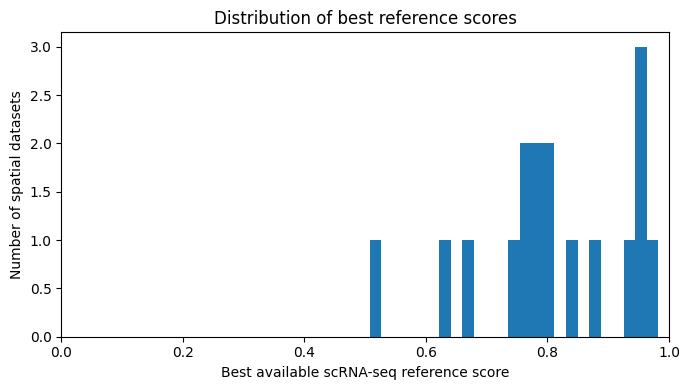

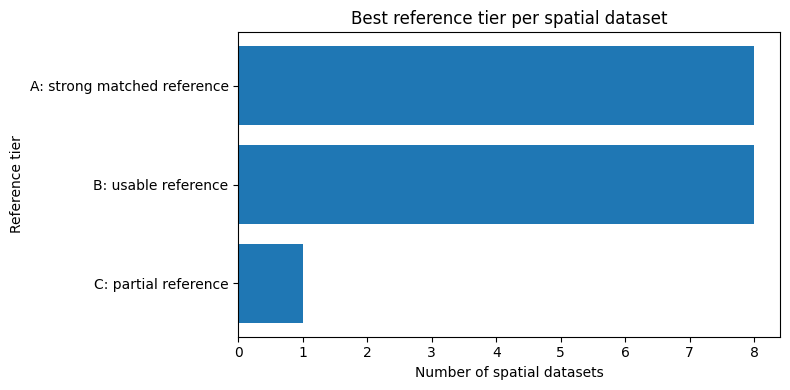

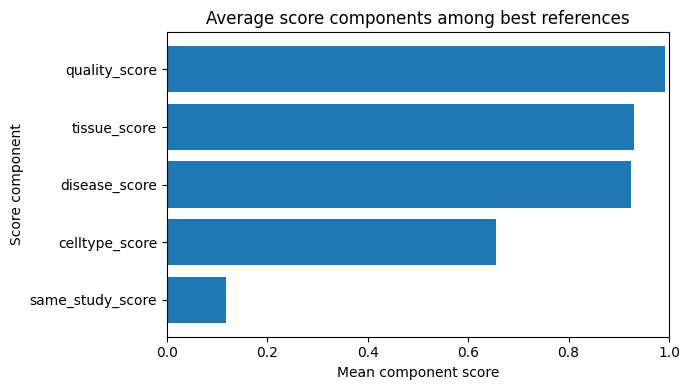

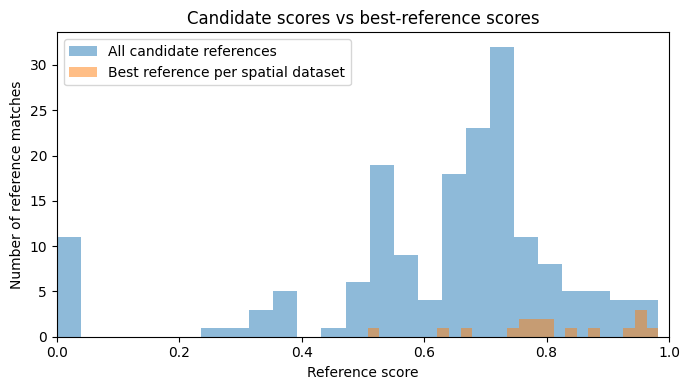

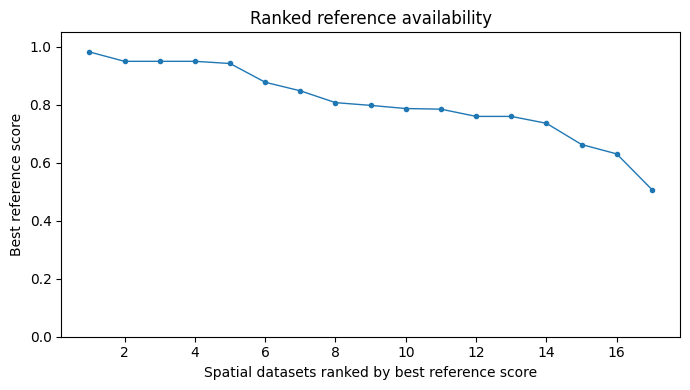

In [32]:
best_refs = plot_reference_score_report(reference_scores)

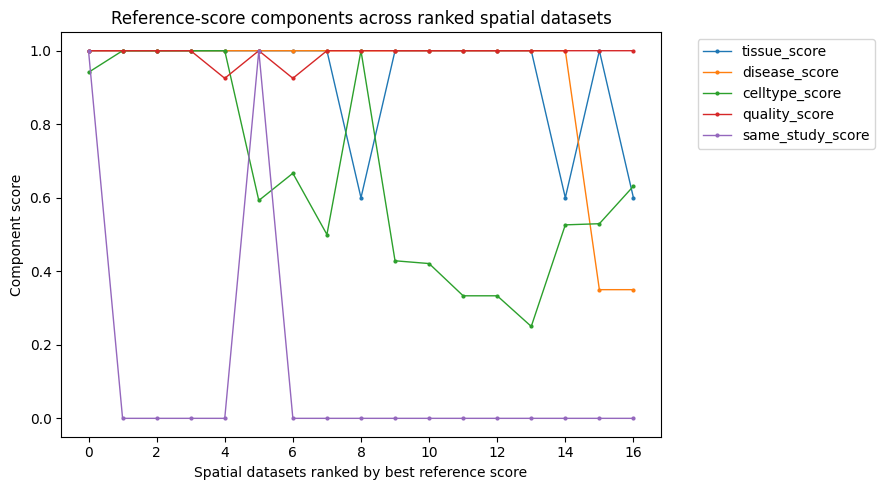

In [33]:
component_cols = [
    "tissue_score",
    "disease_score",
    "celltype_score",
    "quality_score",
    "same_study_score",
]

ranked = best_refs.sort_values("score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 5))

for col in component_cols:
    plt.plot(
        np.arange(len(ranked)),
        ranked[col],
        marker="o",
        markersize=2,
        linewidth=1,
        label=col,
    )

plt.xlabel("Spatial datasets ranked by best reference score")
plt.ylabel("Component score")
plt.title("Reference-score components across ranked spatial datasets")
plt.ylim(-0.05, 1.05)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
best_refs = best_refs.copy()

# Require at least broad biological evidence of reference relevance
best_refs["has_biological_match"] = (
    (best_refs["tissue_score"] > 0) |
    (best_refs["celltype_score"] > 0) |
    (best_refs["disease_score"] > 0)
)

best_refs["score_gated"] = best_refs["score"].where(
    best_refs["has_biological_match"],
    0.0
)

def score_to_tier_gated(score):
    if score >= 0.85:
        return "A: strong matched reference"
    elif score >= 0.65:
        return "B: usable reference"
    elif score >= 0.40:
        return "C: partial reference"
    elif score > 0:
        return "D: weak reference"
    else:
        return "E: no usable reference"

best_refs["tier_gated"] = best_refs["score_gated"].apply(score_to_tier_gated)

In [ ]:
best_refs["has_tissue_match"] = best_refs["tissue_score"] > 0

best_refs["score_tissue_gated"] = best_refs["score"].where(
    best_refs["has_tissue_match"],
    0.0
)

best_refs["tier_tissue_gated"] = best_refs["score_tissue_gated"].apply(score_to_tier_gated)

In [ ]:
ranked = best_refs.sort_values("score", ascending=False).reset_index(drop=True)
ranked_gated = best_refs.sort_values("score_tissue_gated", ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(len(ranked)),
    ranked["score"],
    marker="o",
    markersize=3,
    linewidth=1,
    label="Original score",
)

plt.plot(
    np.arange(len(ranked_gated)),
    ranked_gated["score_tissue_gated"],
    marker="o",
    markersize=3,
    linewidth=1,
    label="Tissue-gated score",
)

plt.xlabel("Spatial datasets ranked by score")
plt.ylabel("Best reference score")
plt.title("Original vs tissue-gated reference availability")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
tier_order = [
    "A: strong matched reference",
    "B: usable reference",
    "C: partial reference",
    "D: weak reference",
    "E: no usable reference",
]

tier_counts = (
    best_refs["tier_tissue_gated"]
    .value_counts()
    .reindex(tier_order)
    .fillna(0)
)

plt.figure(figsize=(8, 4))
plt.barh(tier_counts.index[::-1], tier_counts.values[::-1])
plt.xlabel("Number of spatial datasets")
plt.ylabel("Reference tier")
plt.title("Reference availability tiers after tissue gating")
plt.tight_layout()
plt.show()

In [ ]:
component_cols = [
    "tissue_score",
    "disease_score",
    "celltype_score",
    "quality_score",
    "same_study_score",
]

matched = best_refs[best_refs["score_tissue_gated"] > 0].copy()
unmatched = best_refs[best_refs["score_tissue_gated"] == 0].copy()

component_compare = pd.DataFrame({
    "matched": matched[component_cols].mean(),
    "unmatched": unmatched[component_cols].mean(),
})

ax = component_compare.plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("Mean component score")
ax.set_title("Component scores for tissue-matched vs unmatched datasets")
ax.set_ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
dropped = best_refs[
    (best_refs["score"] > 0) &
    (best_refs["score_tissue_gated"] == 0)
].copy()

dropped[
    [
        "spatial_dataset_id",
        "ref_dataset_id",
        "ref_dataset_title",
        "ref_collection_name",
        "score",
        "score_tissue_gated",
        "tissue_score",
        "disease_score",
        "celltype_score",
        "quality_score",
        "same_study_score",
        "ref_n_cells",
        "ref_n_donors",
    ]
].sort_values("score", ascending=False).head(30)

In [ ]:
datasets.columns